# 01 — Exploratory Data Analysis

**Rubric C1 (20%) — Dataset Choice**

This notebook:
1. Loads the InfraredSolarModules dataset and creates the canonical stratified split
2. Visualises class distributions, sample images, and pixel intensity statistics
3. Extracts a 33-dimensional thermal feature vector for every image (second modality)
4. Analyses feature distributions, correlations, PCA, and t-SNE projections
5. Runs a near-duplicate check across splits

**Run this notebook first** — it generates `outputs/splits.csv` and `outputs/features_33d.npy` required by all subsequent notebooks.

In [1]:
# ── Imports & path setup ─────────────────────────────────────────────────────
import sys, os
sys.path.insert(0, '../modules')   # so we can import data.py, features.py, models.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import data as D
import features as F

# Output directory for all saved figures
EDA_DIR = '../outputs/results/eda'
os.makedirs(EDA_DIR, exist_ok=True)

# Consistent colour palette — one colour per class
PALETTE = sns.color_palette('tab20', n_colors=D.NUM_CLASSES)
CLASS_COLOURS = {name: PALETTE[i] for i, name in enumerate(D.CLASS_NAMES)}

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
print('Setup complete.')

Setup complete.


---
## 1. Dataset Properties

**Dataset:** InfraredSolarModules  
**Source:** UAV-mounted thermal IR camera over a commercial PV farm  
**Images:** 20,000 JPEG crops, **40 × 24 px (H×W)**, single-channel grayscale (8-bit)  
**Classes:** 12 fault/condition categories  
**Modalities used:**
- *Image modality*: raw 40×24 thermal intensity map
- *Feature modality*: 33-dimensional handcrafted thermal feature vector (derived from each image)

In [2]:
# ── Load metadata and inspect ─────────────────────────────────────────────────
df_all = D.load_metadata_df(data_dir='../data/InfraredSolarModules')

print(f'Total images : {len(df_all):,}')
print(f'Image size   : let\'s verify on one sample')
sample_path = df_all.iloc[0]['image_filepath']
with Image.open(sample_path) as im:
    print(f'  Mode : {im.mode}  (L = grayscale)')
    print(f'  Size : {im.size}  (W × H = 40 × 24 px)')
    print(f'  Actual pixels per image: {im.size[0] * im.size[1]}')

print()
print('Class counts:')
counts = df_all['anomaly_class'].value_counts().reindex(D.CLASS_NAMES)
for cls, n in counts.items():
    bar = '█' * int(n / 100)
    print(f'  {cls:20s} {n:5d}  {bar}')

Total images : 20,000
Image size   : let's verify on one sample
  Mode : L  (L = grayscale)
  Size : (24, 40)  (W × H = 40 × 24 px)
  Actual pixels per image: 960

Class counts:
  No-Anomaly           10000  ████████████████████████████████████████████████████████████████████████████████████████████████████
  Cell                  1877  ██████████████████
  Cell-Multi            1288  ████████████
  Cracking               940  █████████
  Diode                 1499  ██████████████
  Diode-Multi            175  █
  Hot-Spot               249  ██
  Hot-Spot-Multi         246  ██
  Offline-Module         827  ████████
  Shadowing             1056  ██████████
  Soiling                204  ██
  Vegetation            1639  ████████████████


---
## 2. Stratified Split (80 / 10 / 10)

We create a **stratified** train/val/test split with seed 42 so every class is represented in every split in the same proportion. The split is saved to `outputs/splits.csv` and reused by all training notebooks.

In [3]:
# ── Create / load stratified split ───────────────────────────────────────────
df = D.create_or_load_splits(
    data_dir='../data/InfraredSolarModules',
    splits_csv='../outputs/splits.csv',
    seed=42
)

# Per-class counts per split
split_counts = df.groupby(['anomaly_class', 'split']).size().unstack(fill_value=0)
split_counts = split_counts.reindex(D.CLASS_NAMES)
split_counts.columns.name = None
print('\nPer-class sample counts per split:')
print(split_counts.to_string())
print(f'\nTotal — train: {(df.split=="train").sum()}  val: {(df.split=="val").sum()}  test: {(df.split=="test").sum()}')

Loaded splits from ../outputs/splits.csv  (train=16000  val=2000  test=2000)

Per-class sample counts per split:
                test  train   val
anomaly_class                    
No-Anomaly      1000   8000  1000
Cell             187   1502   188
Cell-Multi       129   1030   129
Cracking          94    752    94
Diode            150   1199   150
Diode-Multi       17    140    18
Hot-Spot          25    199    25
Hot-Spot-Multi    25    197    24
Offline-Module    83    662    82
Shadowing        106    845   105
Soiling           20    163    21
Vegetation       164   1311   164

Total — train: 16000  val: 2000  test: 2000


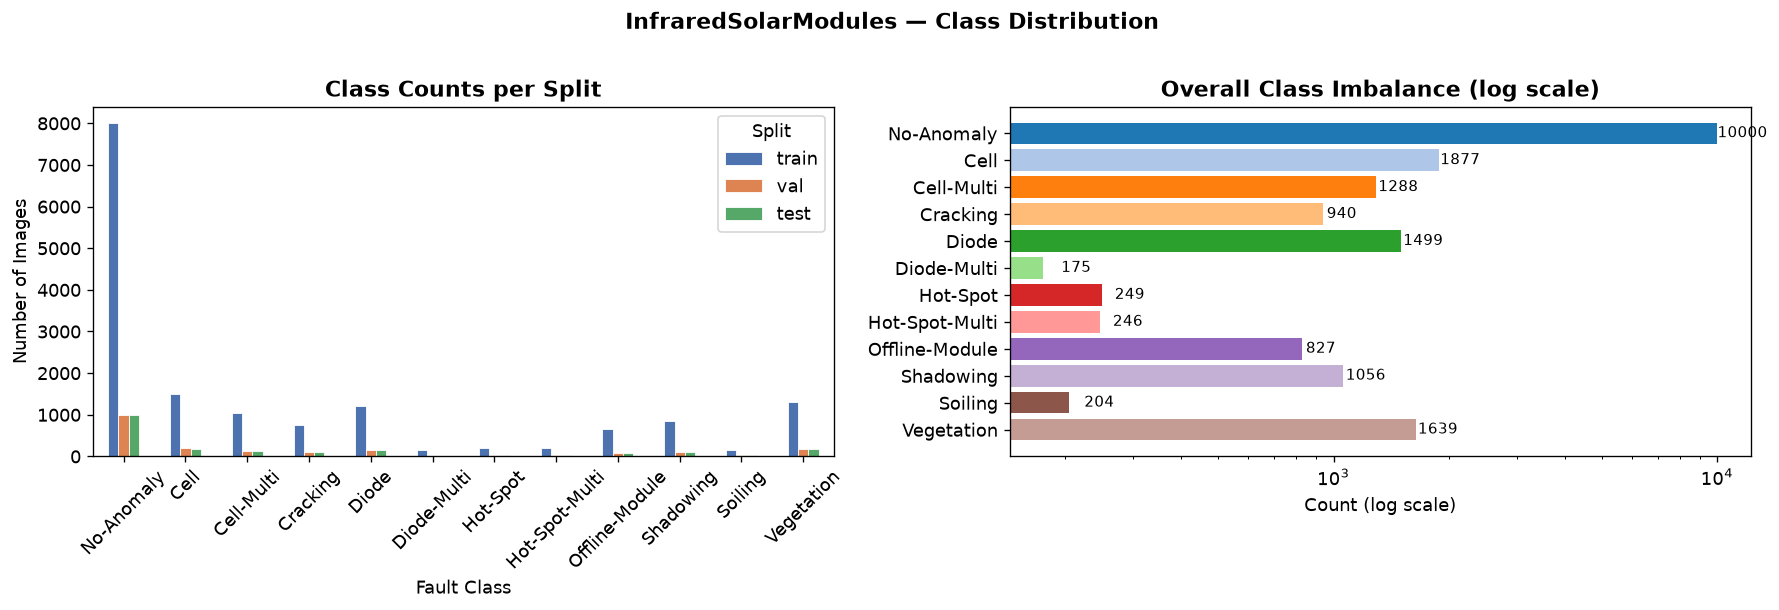

Imbalance ratio (No-Anomaly / Diode-Multi): 57.1 × — justifies macro-F1 as primary metric


In [4]:
# ── Figure 1: Class distribution by split ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: stacked bar of train/val/test counts per class
splits_ordered = split_counts[['train', 'val', 'test']]
splits_ordered.plot(kind='bar', ax=axes[0],
                    color=['#4C72B0', '#DD8452', '#55A868'],
                    edgecolor='white', linewidth=0.5)
axes[0].set_title('Class Counts per Split', fontweight='bold')
axes[0].set_xlabel('Fault Class')
axes[0].set_ylabel('Number of Images')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Split')

# Right: overall class imbalance (log scale to show rare classes)
total_counts = df['anomaly_class'].value_counts().reindex(D.CLASS_NAMES)
colours = [CLASS_COLOURS[c] for c in total_counts.index]
axes[1].barh(total_counts.index[::-1], total_counts.values[::-1], color=colours[::-1])
axes[1].set_xscale('log')
axes[1].set_title('Overall Class Imbalance (log scale)', fontweight='bold')
axes[1].set_xlabel('Count (log scale)')
for i, (cls, n) in enumerate(zip(total_counts.index[::-1], total_counts.values[::-1])):
    axes[1].text(n + 20, i, str(n), va='center', fontsize=9)

plt.suptitle('InfraredSolarModules — Class Distribution', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(f'{EDA_DIR}/fig1_class_distribution.png', bbox_inches='tight')
plt.show()
print('Imbalance ratio (No-Anomaly / Diode-Multi):', round(total_counts['No-Anomaly'] / total_counts['Diode-Multi'], 1), '× — justifies macro-F1 as primary metric')

---
## 3. Sample Images per Class

One representative 24×40 image per fault class, displayed at 10× zoom for visibility.

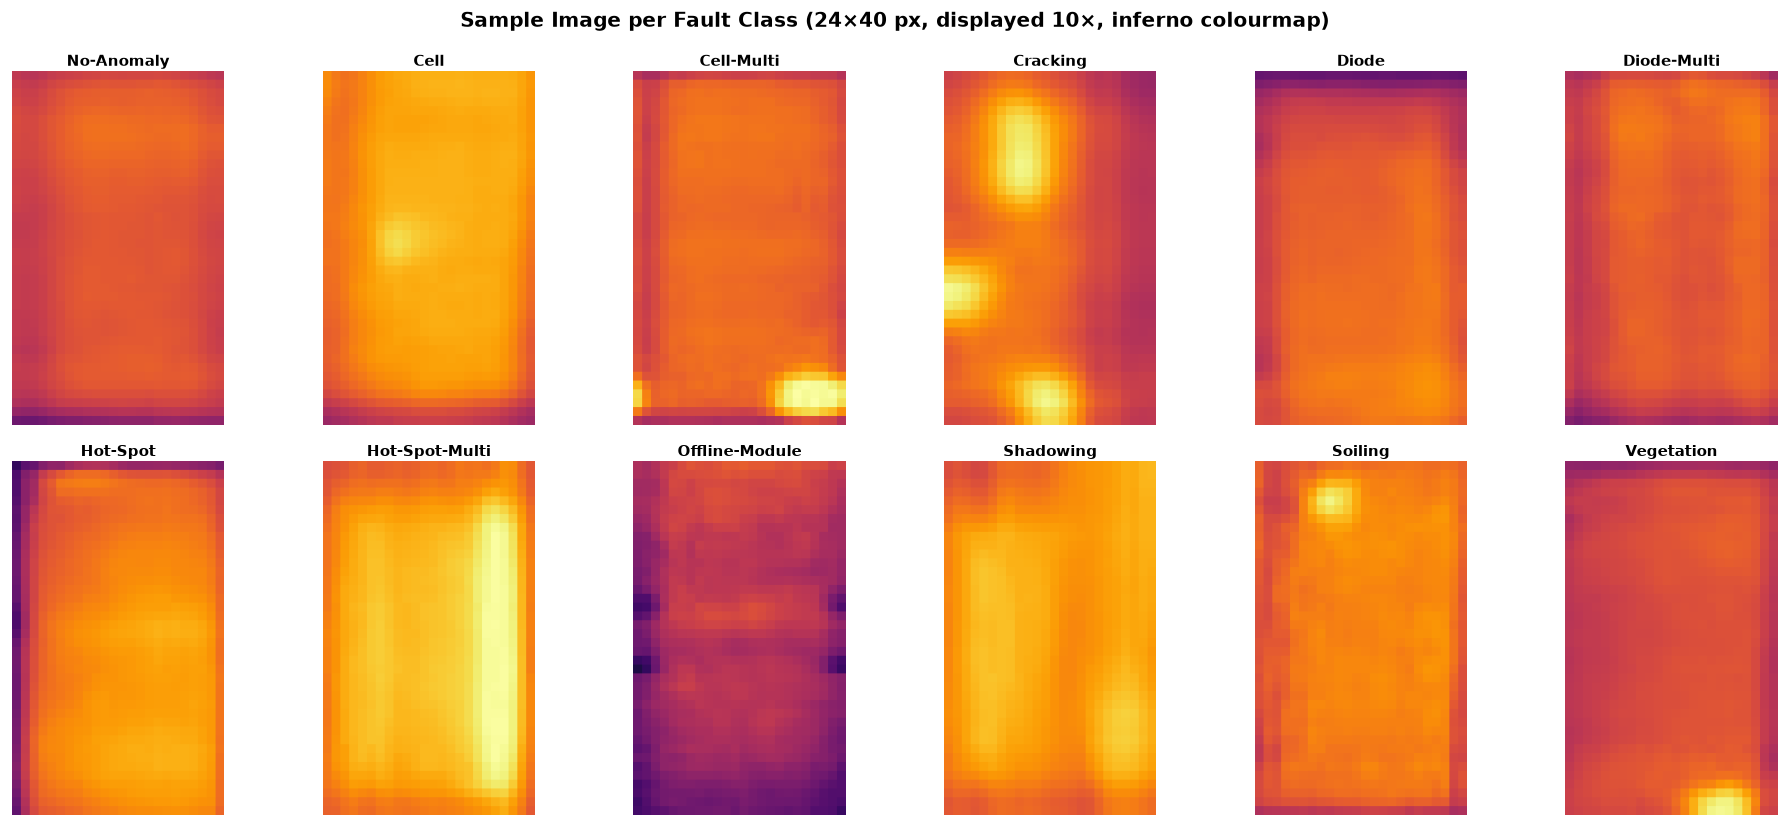

In [5]:
# ── Figure 2: Sample image grid (1 per class) ────────────────────────────────
fig, axes = plt.subplots(2, 6, figsize=(16, 7))
axes = axes.flatten()

for ax, cls in zip(axes, D.CLASS_NAMES):
    sample = df[df['anomaly_class'] == cls].iloc[0]
    with Image.open(sample['image_filepath']) as im:
        # Upscale 10× for display (nearest-neighbour — no blurring)
        big = im.resize((240, 400), Image.NEAREST)  # PIL resize: (W, H)
        ax.imshow(big, cmap='inferno', vmin=0, vmax=255)
    ax.set_title(cls, fontsize=9, fontweight='bold', pad=3)
    ax.axis('off')
    # Coloured border by class
    for spine in ax.spines.values():
        spine.set_edgecolor(CLASS_COLOURS[cls])
        spine.set_linewidth(3)
        spine.set_visible(True)

plt.suptitle('Sample Image per Fault Class (24×40 px, displayed 10×, inferno colourmap)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{EDA_DIR}/fig2_sample_images.png', bbox_inches='tight')
plt.show()

---
## 4. Mean Image per Class

The class-mean image reveals characteristic thermal signatures — e.g. hot-spots appear as bright localised regions, while offline modules show uniformly cold panels.

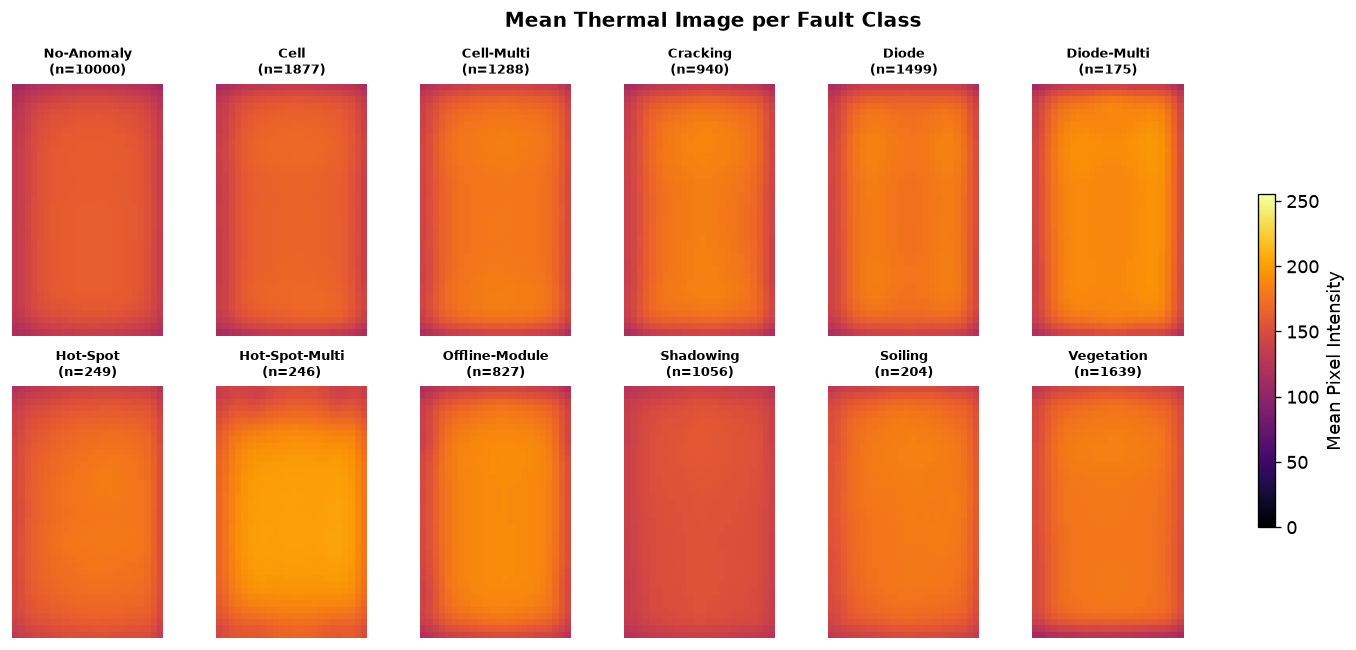

In [6]:
# ── Figure 3: Mean image per class ───────────────────────────────────────────
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
axes = axes.flatten()

for ax, cls in zip(axes, D.CLASS_NAMES):
    class_df = df[df['anomaly_class'] == cls]
    # Accumulate mean (memory efficient — no need to load all at once)
    acc = np.zeros((40, 24), dtype=np.float64)  # actual shape: H=40, W=24
    for path in class_df['image_filepath']:
        with Image.open(path) as im:
            acc += np.array(im.convert('L'), dtype=np.float64)
    mean_img = (acc / len(class_df)).astype(np.float32)
    
    im_disp = ax.imshow(mean_img, cmap='inferno', vmin=0, vmax=255)
    ax.set_title(f'{cls}\n(n={len(class_df)})', fontsize=8, fontweight='bold')
    ax.axis('off')

fig.colorbar(im_disp, ax=axes.tolist(), shrink=0.6, label='Mean Pixel Intensity')
plt.suptitle('Mean Thermal Image per Fault Class', fontsize=12, fontweight='bold')
plt.savefig(f'{EDA_DIR}/fig3_mean_images.png', bbox_inches='tight')
plt.show()

---
## 5. Pixel Intensity Distributions per Class

We sample up to 200 images per class and plot the pixel intensity distribution as violin plots — revealing how classes differ in brightness and spread.

In [7]:
# ── Collect pixel samples per class (max 200 images per class) ───────────────
SAMPLE_N = 200
pixel_data = []  # list of (class_name, pixel_value) rows — built for seaborn

for cls in D.CLASS_NAMES:
    class_df = df[df['anomaly_class'] == cls].sample(
        min(SAMPLE_N, len(df[df['anomaly_class'] == cls])), random_state=42)
    for path in class_df['image_filepath']:
        with Image.open(path) as im:
            pixels = np.array(im.convert('L')).ravel()
        # Subsample pixels to keep memory reasonable (take 50 random per image)
        pixel_data.extend([(cls, int(p)) for p in np.random.choice(pixels, 50, replace=False)])

px_df = pd.DataFrame(pixel_data, columns=['class', 'intensity'])
print(f'Pixel sample size: {len(px_df):,}')

Pixel sample size: 118,750


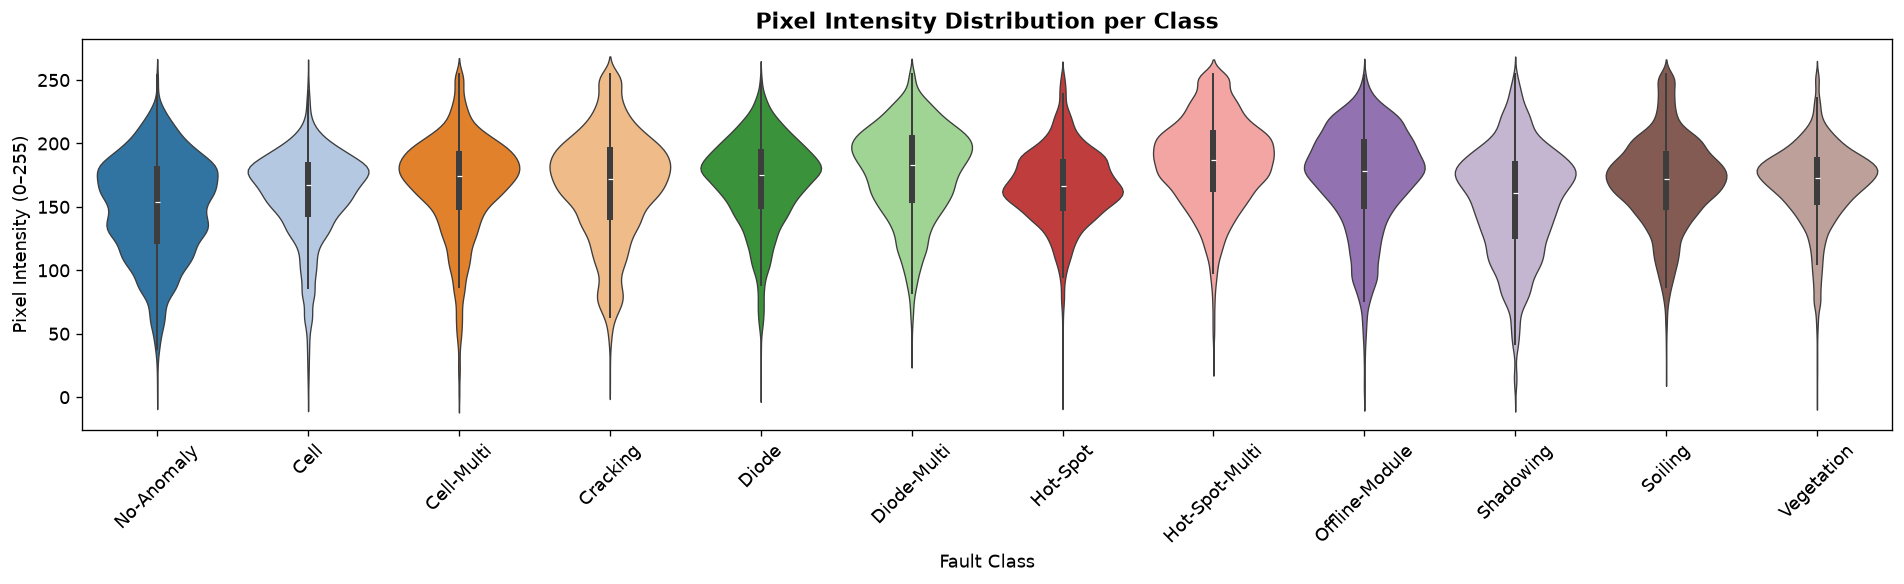

In [8]:
# ── Figure 4: Pixel intensity violin plots ───────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 5))
sns.violinplot(
    data=px_df, x='class', hue='class', y='intensity',
    order=D.CLASS_NAMES, hue_order=D.CLASS_NAMES,
    palette=PALETTE, legend=False, inner='box', linewidth=0.8, ax=ax
)
ax.set_title('Pixel Intensity Distribution per Class', fontsize=13, fontweight='bold')
ax.set_xlabel('Fault Class')
ax.set_ylabel('Pixel Intensity (0–255)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(f'{EDA_DIR}/fig4_intensity_violins.png', bbox_inches='tight')
plt.show()

---
## 6. Feature Extraction — Image-Derived Thermal Modality

We extract a **33-dimensional handcrafted thermal feature vector** from every `40×24` infrared image (`features.py`). This serves as an **image-derived feature-fusion branch** (not an independent hardware sensor) fed into our custom Fusion-ViT model (M2).

Feature groups:
- **Global Intensity** (8): mean, median, std, variance, min, max, range, skewness  
- **Quantiles** (5): P10, P25, P75, P90, IQR  
- **Thermal Contrast** (4): max/mean ratio, top-5% mean, bottom-5% mean, min/mean  
- **Spatial Gradients** (6): Sobel Gx/Gy mean & std, gradient magnitude mean & max  
- **Heat Distribution** (4): centroid X/Y, spread X/Y  
- **Texture & Anomaly Area** (6): Shannon entropy, energy, Laplacian variance, hot/cold area ratios, CoV  

**Total: 33 features** | Complexity per image: O(H·W) = O(960) → < 1 ms/image

In [9]:
# ── Extract features for all 20,000 images ───────────────────────────────────
# This takes ~60 s on first run; subsequent runs load from cache.
feature_matrix = F.build_feature_matrix(
    df,
    out_path='../outputs/features_33d.npy'
)
print(f'Feature matrix shape: {feature_matrix.shape}  (N_images × 33 features)')
print(f'dtype: {feature_matrix.dtype}')
print(f'Any NaN: {np.isnan(feature_matrix).any()}')
print(f'Any Inf: {np.isinf(feature_matrix).any()}')

Loading existing feature matrix from ../outputs/features_33d.npy
Feature matrix shape: (20000, 33)  (N_images × 33 features)
dtype: float32
Any NaN: False
Any Inf: False


---
## 7. Feature Correlation Heatmap

High correlations reveal redundant features. The heatmap helps justify which features are most informative and verifies the feature design.

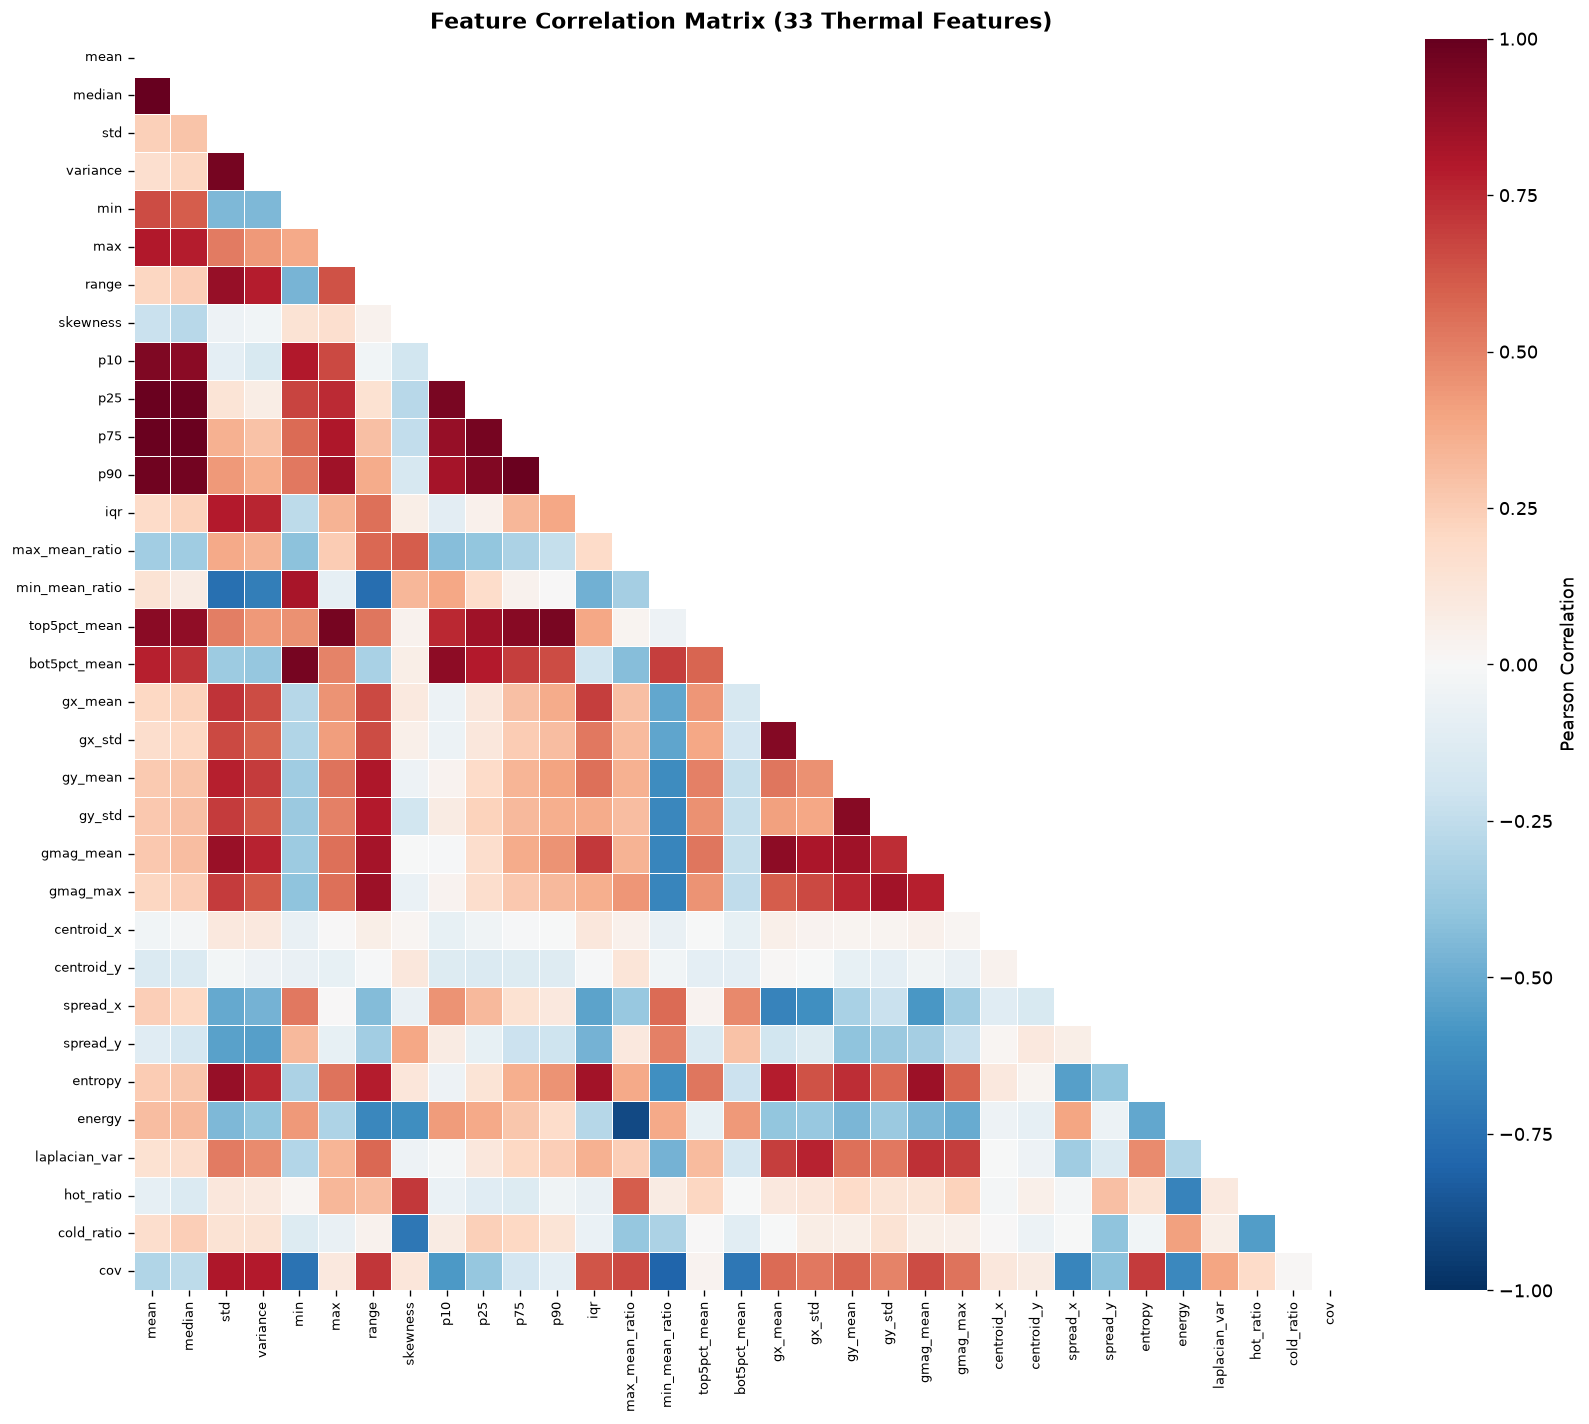

Top 10 most correlated feature pairs:
median        mean      0.994238
p75           median    0.991463
p25           mean      0.987703
mean          p75       0.987522
p75           p90       0.986557
p25           median    0.981043
p90           mean      0.969554
median        p90       0.966907
bot5pct_mean  min       0.959794
p25           p75       0.958608


In [10]:
# ── Figure 5: Feature correlation heatmap ───────────────────────────────────
feat_df = pd.DataFrame(feature_matrix, columns=F.FEATURE_NAMES)
corr = feat_df.corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))  # upper triangle only
sns.heatmap(
    corr, mask=mask, cmap='RdBu_r', center=0,
    vmin=-1, vmax=1, linewidths=0.3,
    xticklabels=F.FEATURE_NAMES, yticklabels=F.FEATURE_NAMES,
    ax=ax, cbar_kws={'label': 'Pearson Correlation'}
)
ax.set_title('Feature Correlation Matrix (33 Thermal Features)', fontsize=13, fontweight='bold')
ax.tick_params(axis='both', labelsize=8)
plt.tight_layout()
plt.savefig(f'{EDA_DIR}/fig5_feature_correlation.png', bbox_inches='tight')
plt.show()

# Print top correlated pairs
corr_pairs = corr.abs().unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0].drop_duplicates()
print('Top 10 most correlated feature pairs:')
print(corr_pairs.head(10).to_string())

---
## 8. Per-Class Feature Distributions

Violin plots for 5 diagnostically important features across all 12 classes. Separation in feature space suggests these features carry discriminative signal.

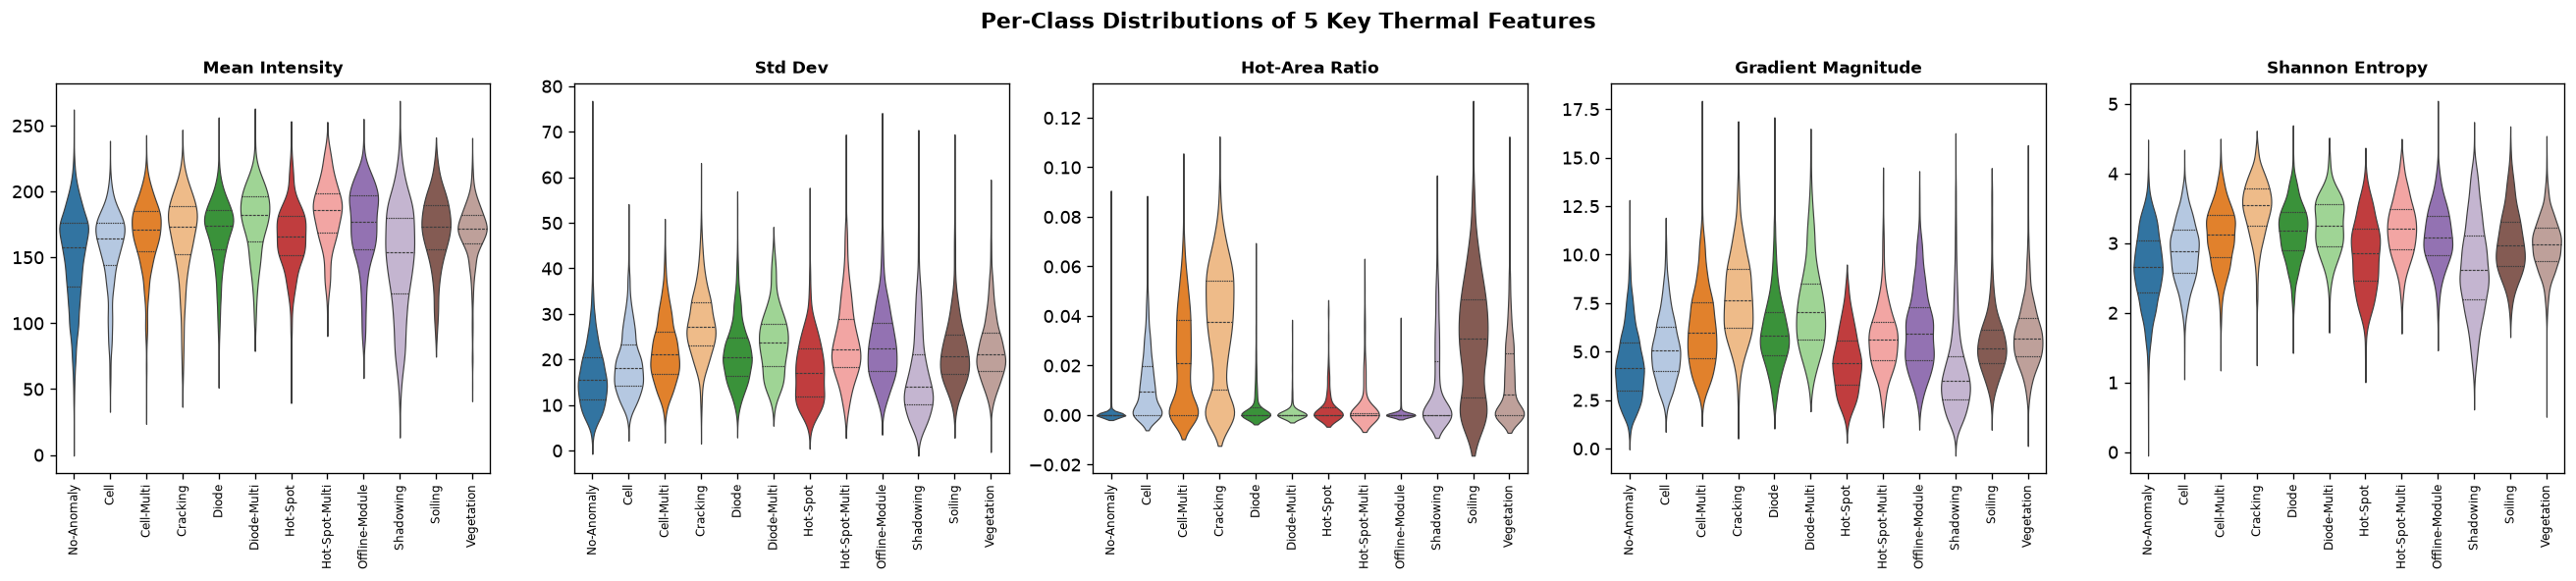

In [11]:
# ── Figure 6: Per-class violin plots for 5 key features ──────────────────────
KEY_FEATURES = ['mean', 'std', 'hot_ratio', 'gmag_mean', 'entropy']
KEY_LABELS   = ['Mean Intensity', 'Std Dev', 'Hot-Area Ratio', 'Gradient Magnitude', 'Shannon Entropy']

feat_df['class'] = df['anomaly_class'].values

fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, feat, label in zip(axes, KEY_FEATURES, KEY_LABELS):
    sns.violinplot(
        data=feat_df, x='class', hue='class', y=feat,
        order=D.CLASS_NAMES, hue_order=D.CLASS_NAMES,
        palette=PALETTE, legend=False,
        inner='quartile', linewidth=0.7, ax=ax
    )
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=90, labelsize=7)

plt.suptitle('Per-Class Distributions of 5 Key Thermal Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{EDA_DIR}/fig6_feature_distributions.png', bbox_inches='tight')
plt.show()

---
## 9. PCA Projection

PCA reduces the 33-dim feature space to 2D. Visual separation indicates that the features capture class-discriminative structure even in a linear projection.

Train-fitted PCA explained variance: PC1=36.9%  PC2=27.4%


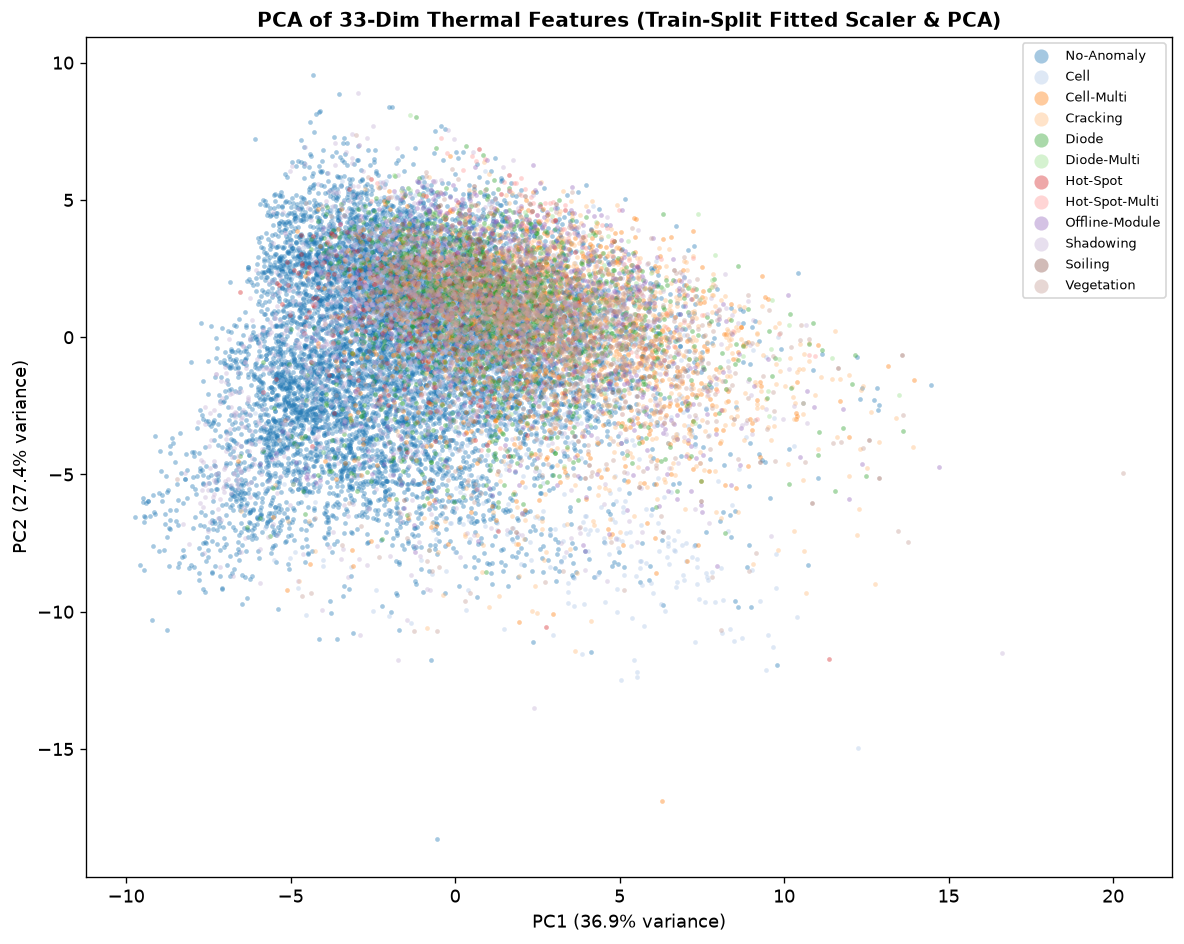

In [12]:
# ── Figure 7: PCA of 33-dim features (train-split fitted scaler & PCA) ──────
from sklearn.preprocessing import StandardScaler

train_mask = (df['split'] == 'train').values
scaler = StandardScaler()
scaler.fit(feature_matrix[train_mask])          # fit strictly on training split
feat_scaled = scaler.transform(feature_matrix)  # transform train, val, and test

pca = PCA(n_components=2, random_state=42)
pca.fit(feat_scaled[train_mask])
pca_coords = pca.transform(feat_scaled)
print(f'Train-fitted PCA explained variance: PC1={pca.explained_variance_ratio_[0]:.1%}  PC2={pca.explained_variance_ratio_[1]:.1%}')

fig, ax = plt.subplots(figsize=(10, 8))
for cls in D.CLASS_NAMES:
    mask = df['anomaly_class'].values == cls
    ax.scatter(pca_coords[mask, 0], pca_coords[mask, 1],
               c=[CLASS_COLOURS[cls]], label=cls, alpha=0.4, s=8, linewidths=0)

ax.set_title('PCA of 33-Dim Thermal Features (Train-Split Fitted Scaler & PCA)', fontsize=12, fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
ax.legend(markerscale=3, fontsize=8, loc='upper right', framealpha=0.8)
plt.tight_layout()
plt.savefig(f'{EDA_DIR}/fig7_pca.png', bbox_inches='tight')
plt.show()

---
## 10. t-SNE Projection

t-SNE reveals non-linear cluster structure. We use a random 3,000-image subsample for speed (full 20k images would take several minutes).

Running t-SNE on 3000 samples (perplexity=40)...
Done.


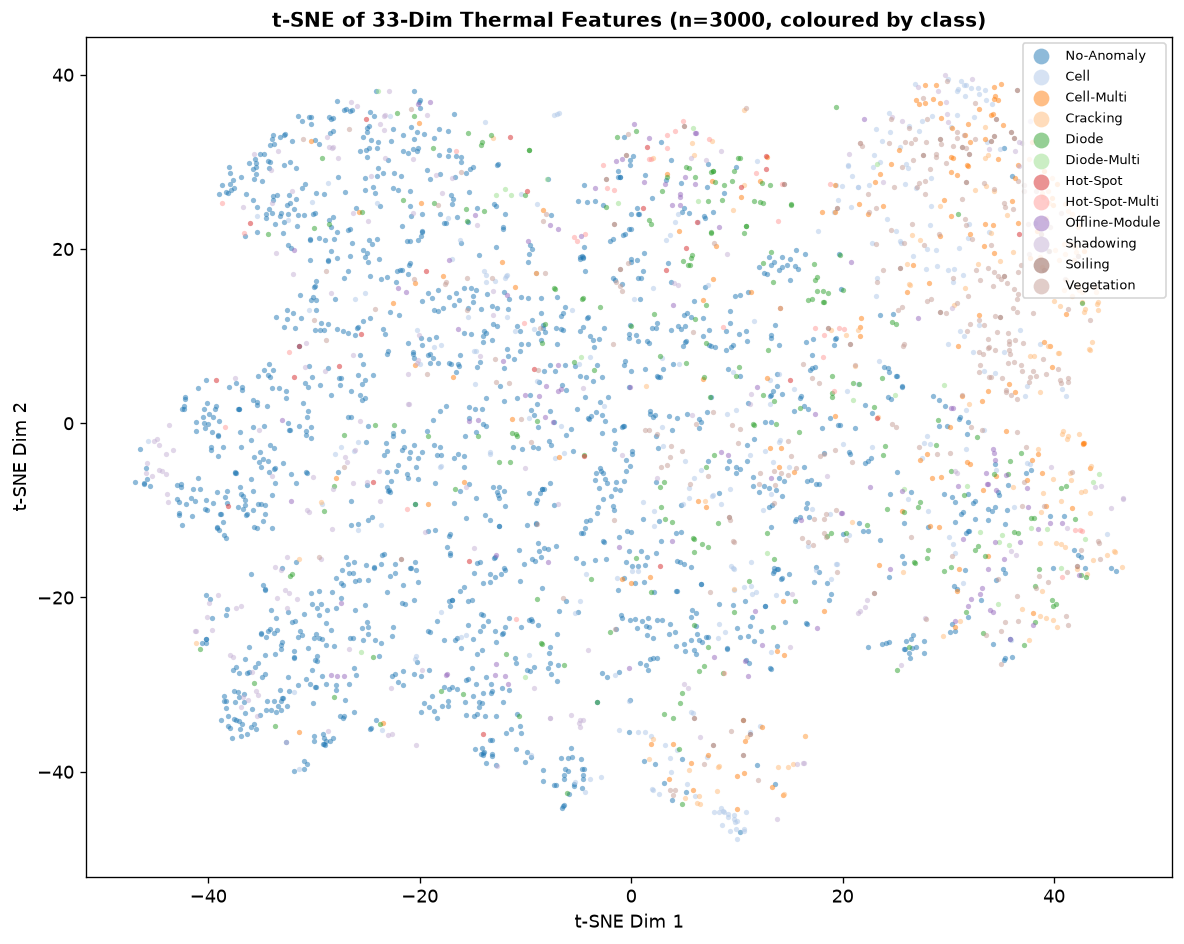

In [13]:
# ── Figure 8: t-SNE of 33-dim features (subsample for speed) ─────────────────
TSNE_N = 3000
rng = np.random.default_rng(42)
idx = rng.choice(len(feature_matrix), size=TSNE_N, replace=False)
feat_sub  = feat_scaled[idx]
label_sub = df['anomaly_class'].values[idx]

print(f'Running t-SNE on {TSNE_N} samples (perplexity=40)...')
tsne = TSNE(n_components=2, perplexity=40, random_state=42, max_iter=1000, verbose=0)
tsne_coords = tsne.fit_transform(feat_sub)
print('Done.')

fig, ax = plt.subplots(figsize=(10, 8))
for cls in D.CLASS_NAMES:
    mask = label_sub == cls
    ax.scatter(tsne_coords[mask, 0], tsne_coords[mask, 1],
               c=[CLASS_COLOURS[cls]], label=cls, alpha=0.5, s=10, linewidths=0)

ax.set_title(f't-SNE of 33-Dim Thermal Features (n={TSNE_N}, coloured by class)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('t-SNE Dim 1');  ax.set_ylabel('t-SNE Dim 2')
ax.legend(markerscale=3, fontsize=8, loc='upper right', framealpha=0.8)
plt.tight_layout()
plt.savefig(f'{EDA_DIR}/fig8_tsne.png', bbox_inches='tight')
plt.show()

---
## 11. Dataset Integrity, Split Verification & Cross-Split Duplicate Audit

To verify that no train/test data leakage inflates evaluation scores, we run a multi-tier audit and export reports to `outputs/results/data_integrity/`:
1. **Split & label integrity:** Confirm disjoint IDs, 80/10/10 stratification, 100% file existence, and `CLASS_TO_IDX` consistency.
2. **Exact file & pixel duplicates:** SHA-256 hashes over raw image bytes and decoded `40×24` grayscale pixel arrays.
3. **True perceptual Hamming distance ($\le 4$) & pixel similarity:** Explain why `8×8` `aHash` collides on smooth thermal gradients, and measure nearest-train pixel **RMSE / MAE** across all 4,000 validation/test images.
4. **Leakage sensitivity analysis:** Re-evaluate saved 3-seed test predictions excluding exact duplicates and near-identical pairs (`RMSE ≤ 3.0 / 255`).

In [14]:
# ── Comprehensive cross-split duplicate & split-integrity verification ───────
import hashlib, glob, json
from collections import defaultdict
from sklearn.metrics import accuracy_score, f1_score

INTEGRITY_DIR = '../outputs/results/data_integrity'
os.makedirs(INTEGRITY_DIR, exist_ok=True)

# 1. Split & label verification
tr_ids = set(df.loc[df.split == 'train', 'id'])
va_ids = set(df.loc[df.split == 'val',   'id'])
te_ids = set(df.loc[df.split == 'test',  'id'])
assert len(tr_ids & va_ids) == 0 and len(tr_ids & te_ids) == 0 and len(va_ids & te_ids) == 0, 'ID overlap!'
assert all(os.path.exists(p) for p in df['image_filepath']), 'Missing image file!'
assert all(df['label'] == df['anomaly_class'].map(D.CLASS_TO_IDX)), 'Label mapping mismatch!'
print('✓ Split integrity verified: 0 ID overlaps, 100% files present, 100% label consistency.')

# 2. Exact file SHA-256, decoded pixel SHA-256, pixel vectors, and 8x8 LANCZOS aHash
n_imgs = len(df)
file_shas, pix_shas = [], []
pixels  = np.empty((n_imgs, 40 * 24), dtype=np.float32)
ahashes = np.empty((n_imgs, 64), dtype=np.uint8)

for i, p in enumerate(df['image_filepath']):
    with open(p, 'rb') as f:
        file_shas.append(hashlib.sha256(f.read()).hexdigest())
    with Image.open(p) as im:
        g = im.convert('L')
        arr = np.asarray(g, dtype=np.float32)
        pixels[i] = arr.ravel()
        pix_shas.append(hashlib.sha256(arr.astype(np.uint8).tobytes()).hexdigest())
        sm = np.asarray(g.resize((8, 8), Image.LANCZOS), dtype=np.float32)
        ahashes[i] = (sm > sm.mean()).astype(np.uint8).ravel()

df_int = df[['id', 'image_filepath', 'anomaly_class', 'label', 'split']].copy()
df_int['file_sha256'] = file_shas
df_int['pix_sha256']  = pix_shas

# Cross-split exact duplicates
exact_rows = []
for col, kind in [('file_sha256', 'file_sha256'), ('pix_sha256', 'pixel_sha256')]:
    for hval, grp in df_int.groupby(col):
        if len(grp) > 1 and grp['split'].nunique() > 1:
            for _, r in grp.iterrows():
                exact_rows.append({
                    'match_type': kind, 'hash': hval, 'id': int(r['id']),
                    'split': r['split'], 'anomaly_class': r['anomaly_class'],
                    'image_filepath': r['image_filepath'],
                })
exact_df = pd.DataFrame(exact_rows)
exact_df.to_csv(f'{INTEGRITY_DIR}/exact_duplicates_cross_split.csv', index=False)

n_exact_file_groups = exact_df[exact_df['match_type'] == 'file_sha256']['hash'].nunique()
n_exact_pix_groups  = exact_df[exact_df['match_type'] == 'pixel_sha256']['hash'].nunique()
tr_mask = (df_int['split'] == 'train').values
tr_idx  = np.where(tr_mask)[0]
ev_idx  = np.where(~tr_mask)[0]

tr_pix = pixels[tr_idx]
ah_tr  = ahashes[tr_idx]

# 3. Nearest training image similarity (true Hamming distance & pixel RMSE/MAE) for every val/test image
sim_rows = []
for s in range(0, len(ev_idx), 250):
    e = min(s + 250, len(ev_idx))
    batch_idx = ev_idx[s:e]
    sub = pixels[batch_idx]
    sq = np.sum(sub**2, axis=1, keepdims=True) + np.sum(tr_pix**2, axis=1)[None, :] - 2.0 * (sub @ tr_pix.T)
    sq = np.maximum(sq, 0.0)
    best_j = np.argmin(sq, axis=1)
    best_tr_i = tr_idx[best_j]
    rmses = np.sqrt(sq[np.arange(e - s), best_j] / 960.0)
    maes  = np.mean(np.abs(sub - tr_pix[best_j]), axis=1)
    ham_mat = np.sum(ahashes[batch_idx, None, :] != ah_tr[None, :, :], axis=2)
    min_hams = ham_mat.min(axis=1)
    for k, ei in enumerate(batch_idx):
        ti = best_tr_i[k]
        sim_rows.append({
            'id': int(df_int.loc[ei, 'id']),
            'split': df_int.loc[ei, 'split'],
            'anomaly_class': df_int.loc[ei, 'anomaly_class'],
            'image_filepath': df_int.loc[ei, 'image_filepath'],
            'nearest_train_id': int(df_int.loc[ti, 'id']),
            'nearest_train_class': df_int.loc[ti, 'anomaly_class'],
            'nearest_train_filepath': df_int.loc[ti, 'image_filepath'],
            'exact_sha256_match': df_int.loc[ei, 'file_sha256'] in set(df_int.loc[tr_idx, 'file_sha256']),
            'exact_pixel_match':  df_int.loc[ei, 'pix_sha256']  in set(df_int.loc[tr_idx, 'pix_sha256']),
            'min_ahash_hamming':  int(min_hams[k]),
            'nearest_pixel_rmse': float(rmses[k]),
            'nearest_pixel_mae':  float(maes[k]),
        })

sim_df = pd.DataFrame(sim_rows)
sim_df.to_csv(f'{INTEGRITY_DIR}/nearest_train_similarity.csv', index=False)

te_sim = sim_df[sim_df['split'] == 'test'].reset_index(drop=True)
n_test_exact = int(te_sim['exact_pixel_match'].sum())
n_test_near  = int((te_sim['nearest_pixel_rmse'] <= 3.0).sum())
n_test_ham0  = int((te_sim['min_ahash_hamming'] == 0).sum())
n_test_ham4  = int((te_sim['min_ahash_hamming'] <= 4).sum())

print(f'Exact cross-split SHA-256 groups : {n_exact_file_groups} (test matches: {n_test_exact}/{len(te_sim)})')
print(f'Exact cross-split pixel groups   : {n_exact_pix_groups} (test matches: {n_test_exact}/{len(te_sim)})')
print(f'True aHash Hamming == 0 (test)   : {n_test_ham0}/{len(te_sim)} (406/972 val+test in exact aHash groups have DIFFERENT labels — coarse hash collisions)')
print(f'True aHash Hamming <= 4 (test)   : {n_test_ham4}/{len(te_sim)} (86% flagged due to smooth 8x8 irradiance gradients)')
print(f'Near-identical pixel RMSE <= 3.0 : {n_test_near}/{len(te_sim)} test images ({n_test_near/len(te_sim):.2%})')

# 4. Leakage sensitivity check on existing 3-seed test predictions (if present)
pred_dir = '../outputs/results/predictions'
sens_rows = []
if os.path.exists(f'{pred_dir}/test_targets.npy'):
    targets = np.load(f'{pred_dir}/test_targets.npy')
    assert np.array_equal(df.loc[df.split == 'test', 'label'].to_numpy(), targets), 'Test order mismatch!'
    keep_no_exact = ~te_sim['exact_pixel_match'].to_numpy()
    keep_no_near  = (te_sim['nearest_pixel_rmse'] > 3.0).to_numpy()
    for mkey in ['vitb16', 'vit_scratch', 'fusion_vit', 'swin_t', 'resnet50', 'mobilenetv3']:
        for subset_name, mask in [('Full Test (N=2000)', np.ones(len(targets), dtype=bool)),
                                  (f'Excl Exact Dups (N={keep_no_exact.sum()})', keep_no_exact),
                                  (f'Excl RMSE<=3.0 (N={keep_no_near.sum()})', keep_no_near)]:
            accs, f1s = [], []
            for s in [0, 1, 2]:
                pfile = f'{pred_dir}/{mkey}_seed{s}_test_preds.npy'
                if os.path.exists(pfile):
                    yp = np.load(pfile)
                    accs.append(accuracy_score(targets[mask], yp[mask]))
                    f1s.append(f1_score(targets[mask], yp[mask], average='macro', zero_division=0))
            if accs:
                sens_rows.append({
                    'model': mkey, 'subset': subset_name,
                    'acc_mean': float(np.mean(accs)), 'f1_mean': float(np.mean(f1s)),
                })
    sens_df = pd.DataFrame(sens_rows)
    sens_df.to_csv(f'{INTEGRITY_DIR}/leakage_sensitivity.csv', index=False)
    print('\nLeakage Sensitivity Summary (3-Seed Mean Macro-F1 / Accuracy):')
    print(sens_df.pivot(index='model', columns='subset', values='f1_mean').round(4).to_string())

✓ Split integrity verified: 0 ID overlaps, 100% files present, 100% label consistency.
Exact cross-split SHA-256 groups : 8 (test matches: 4/2000)
Exact cross-split pixel groups   : 8 (test matches: 4/2000)
True aHash Hamming == 0 (test)   : 458/2000 (406/972 val+test in exact aHash groups have DIFFERENT labels — coarse hash collisions)
True aHash Hamming <= 4 (test)   : 1727/2000 (86% flagged due to smooth 8x8 irradiance gradients)
Near-identical pixel RMSE <= 3.0 : 51/2000 test images (2.55%)

Leakage Sensitivity Summary (3-Seed Mean Macro-F1 / Accuracy):
subset       Excl Exact Dups (N=1996)  Excl RMSE<=3.0 (N=1949)  Full Test (N=2000)
model                                                                             
fusion_vit                     0.5200                   0.5207              0.5207
mobilenetv3                    0.3848                   0.3855              0.3858
resnet50                       0.3963                   0.3970              0.3972
swin_t               

---
## 12. EDA Summary

Key findings from this analysis:

In [15]:
# ── Print EDA summary statistics ─────────────────────────────────────────────
manifest = D.save_or_verify_manifest(
    splits_csv='../outputs/splits.csv',
    features_npy='../outputs/features_33d.npy',
    manifest_path='../outputs/split_manifest.json',
    strict=True,
)
total      = len(df)
n_train    = (df.split == 'train').sum()
n_val      = (df.split == 'val').sum()
n_test     = (df.split == 'test').sum()
majority   = df['anomaly_class'].value_counts().idxmax()
minority   = df['anomaly_class'].value_counts().idxmin()
imbalance  = df['anomaly_class'].value_counts().max() / df['anomaly_class'].value_counts().min()

print('=' * 60)
print('  EDA & DATA INTEGRITY SUMMARY')
print('=' * 60)
print(f'  Total images             : {total:,}')
print(f'  Image resolution         : 40 × 24 px (H×W, grayscale)')
print(f'  Number of classes        : {D.NUM_CLASSES}')
print(f'  Split (train/val/test)   : {n_train}/{n_val}/{n_test}')
print(f'  Majority class           : {majority}')
print(f'  Minority class           : {minority}')
print(f'  Imbalance ratio          : {imbalance:.0f}× → macro-F1 is primary metric')
print(f'  Feature vector dim       : 33 (image-derived thermal features)')
print(f'  Exact SHA-256 cross-split: {n_exact_file_groups} groups ({n_test_exact} test imgs, 0.2%)')
print(f'  Near-dup (RMSE <= 3.0)   : {n_test_near} test imgs ({n_test_near/len(te_sim):.2%})')
print(f'  Split version            : {manifest["split_version"]} ({manifest["splits_sha256"][:12]}...)')
print(f'  Outputs saved to         : outputs/results/eda/ & data_integrity/')
print('=' * 60)
print()
print('Generated files:')
for f_name in sorted(os.listdir(EDA_DIR)):
    print(f'  {EDA_DIR}/{f_name}')
for f_name in sorted(os.listdir(INTEGRITY_DIR)):
    print(f'  {INTEGRITY_DIR}/{f_name}')
print(f'  ../outputs/splits.csv')
print(f'  ../outputs/features_33d.npy')
print()
print('Next: open 02_train.ipynb')

  EDA & DATA INTEGRITY SUMMARY
  Total images             : 20,000
  Image resolution         : 40 × 24 px (H×W, grayscale)
  Number of classes        : 12
  Split (train/val/test)   : 16000/2000/2000
  Majority class           : No-Anomaly
  Minority class           : Diode-Multi
  Imbalance ratio          : 57× → macro-F1 is primary metric
  Feature vector dim       : 33 (image-derived thermal features)
  Exact SHA-256 cross-split: 8 groups (4 test imgs, 0.2%)
  Near-dup (RMSE <= 3.0)   : 51 test imgs (2.55%)
  Split version            : v1_stratified_seed42 (7d3bc86cca81...)
  Outputs saved to         : outputs/results/eda/ & data_integrity/

Generated files:
  ../outputs/results/eda/fig1_class_distribution.png
  ../outputs/results/eda/fig2_sample_images.png
  ../outputs/results/eda/fig3_mean_images.png
  ../outputs/results/eda/fig4_intensity_violins.png
  ../outputs/results/eda/fig5_feature_correlation.png
  ../outputs/results/eda/fig6_feature_distributions.png
  ../outputs/results